# Orbit Wars Tutorial

Conquer planets rotating around a sun! Players send fleets of ships between planets to capture territory in a continuous 100x100 space.

## Game Mechanics

- **Planets** produce ships each turn (proportional to their radius)
- **Inner planets** rotate around the central sun; outer planets are static
- **Fleets** fly in straight lines at a given angle from their source planet
- **Fleet speed** scales with fleet size (1 ship = 1/turn, larger fleets up to 6/turn)
- **Combat**: arriving fleet ships are subtracted from the planet's garrison. If the garrison drops below 0, ownership flips
- **Sun**: fleets that hit the sun are destroyed
- **Comets**: temporary planets that fly through the board on elliptical paths
- **Win condition**: most ships (planets + fleets) when time runs out or only one player remains

In [13]:
!pip install --upgrade "kaggle-environments>=1.28.0"

/Users/wang/anaconda3/envs/torch-gpu/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()
/Users/wang/anaconda3/envs/torch-gpu/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()
2867.20s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


In [14]:
from kaggle_environments import make

env = make("orbit_wars", debug=True)
print(f"Environment: {env.name} v{env.version}")
print(f"Players: {env.specification.agents}")
print(f"Max steps: {env.configuration.episodeSteps}")

Environment: orbit_wars v1.0.9
Players: [2, 4]
Max steps: 500


## Understanding the Observation

Each turn your agent receives an observation with:
- `player` - your player ID (0-3)
- `planets` - list of `[id, owner, x, y, radius, ships, production]`
- `fleets` - list of `[id, owner, x, y, angle, from_planet_id, ships]`
- `angular_velocity` - how fast inner planets rotate (radians/turn)

Your agent returns a list of moves: `[from_planet_id, angle_in_radians, num_ships]`

In [15]:
# Run a quick game to see what the observation looks like
env = make("orbit_wars", debug=True)
env.run(["random", "random"])

# Peek at the initial observation
from kaggle_environments.envs.orbit_wars.orbit_wars import Planet

obs = env.steps[1][0].observation  # step 1 = first action step
planets = [Planet(*p) for p in obs.planets]
print(f"Player: {obs.player}")
print(f"Angular velocity: {obs.angular_velocity:.4f} rad/turn")
print(f"\nPlanets ({len(planets)}):")
for p in planets[:6]:
    owner_str = f"Player {p.owner}" if p.owner >= 0 else "Neutral"
    print(f"  id={p.id} owner={owner_str:10s} pos=({p.x:.1f}, {p.y:.1f}) r={p.radius:.1f} ships={p.ships} prod={p.production}")

Player: 0
Angular velocity: 0.0298 rad/turn

Planets (36):
  id=0 owner=Neutral    pos=(76.2, 91.5) r=2.1 ships=17 prod=3
  id=1 owner=Neutral    pos=(8.5, 76.2) r=2.1 ships=17 prod=3
  id=2 owner=Neutral    pos=(91.5, 23.8) r=2.1 ships=17 prod=3
  id=3 owner=Neutral    pos=(23.8, 8.5) r=2.1 ships=17 prod=3
  id=4 owner=Neutral    pos=(86.9, 97.3) r=1.7 ships=28 prod=2
  id=5 owner=Neutral    pos=(2.7, 86.9) r=1.7 ships=28 prod=2


## Visual Debugging: Planetary Map

It's hard to reason about agent behaviour from raw numbers alone. The `draw_orbit_wars()` helper renders the full game state — planets (coloured by owner, labelled with ship count + production), fleets (arrows), comet trajectories, and each player's score on the sun — at any step.

Credit: adapted from [Djenk Ivanov's local debugging notebook](https://www.kaggle.com/code/djenkivanov/orbit-wars-agent-ow-proto-passed-1-000?scriptVersionId=316833310).

In [16]:
import math
import matplotlib.pyplot as plt
import kaggle_environments.envs.orbit_wars.orbit_wars as ow

PLAYER_COLORS = {
    -1: "#888888",
     0: "#1f77b4",
     1: "#ff7f0e",
     2: "#2ca02c",
     3: "#d62728",
}

def draw_orbit_wars(obs, title=None, figsize=(12, 12), save_path=None):
    """Render a game observation as a planetary map.

    Args:
        obs: step observation object.
        title: optional title; defaults to player/step info.
        figsize: matplotlib figure size.
        save_path: if given, save to this path instead of (also) displaying inline.
    """
    planets = [ow.Planet(*p) for p in obs.get("planets", [])]
    fleets  = [ow.Fleet(*f)  for f in obs.get("fleets",  [])]
    player_id       = obs.get("player", None)
    comet_planet_ids = set(obs.get("comet_planet_ids", []))
    angular_velocity = obs.get("angular_velocity", 0.0)

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 100); ax.set_ylim(100, 0); ax.set_aspect("equal")  # ij: row 0 at top
    ax.set_facecolor("#000012")
    ax.grid(color="#222222", linestyle="--", linewidth=0.3, alpha=0.4)

    # Sun
    sun_x, sun_y, sun_r = 50, 50, 10
    ax.add_patch(plt.Circle((sun_x, sun_y), sun_r, color="#ffff66", alpha=0.9, zorder=1))

    # Orbits
    for p in planets:
        r = math.sqrt((p.x - sun_x)**2 + (p.y - sun_y)**2)
        if r > 0:
            ax.add_patch(plt.Circle((sun_x, sun_y), r, color="#444444",
                                    fill=False, linestyle=":", alpha=0.4, zorder=0))

    # Comet trajectories + tails
    for p in planets:
        if p.id not in comet_planet_ids:
            continue
        r = math.sqrt((p.x - sun_x)**2 + (p.y - sun_y)**2)
        if r == 0:
            continue
        angle_now = math.atan2(p.y - sun_y, p.x - sun_x)
        xs, ys = [], []
        for k in range(-40, 41):
            ak = angle_now + angular_velocity * k
            bx = sun_x + r * math.cos(ak)
            by = sun_y + r * math.sin(ak)
            rx, ry = bx - sun_x, by - sun_y
            rl = math.hypot(rx, ry)
            if rl == 0:
                xs.append(bx); ys.append(by); continue
            tx, ty = -ry / rl, rx / rl
            xs.append(bx + 0.3 * tx * (r * 0.1))
            ys.append(by + 0.3 * ty * (r * 0.1))
        ax.plot(xs, ys, color="#ff00ff", linestyle="--", linewidth=0.8, alpha=0.9, zorder=2)
        direction = 1 if angular_velocity >= 0 else -1
        tangent_angle = angle_now + direction * math.pi / 2
        tx0, ty0 = p.x, p.y
        for i in range(4):
            tx1 = tx0 - math.cos(tangent_angle) * 5
            ty1 = ty0 - math.sin(tangent_angle) * 5
            ax.plot([tx0, tx1], [ty0, ty1], color="#ff99ff",
                    linewidth=3.0 * (1.0 - i / 4), alpha=0.9 - 0.15 * i, zorder=6)
            tx0, ty0 = tx1, ty1

    # Planets
    for p in planets:
        color = PLAYER_COLORS.get(p.owner, "#ffffff")
        ax.add_patch(plt.Circle((p.x, p.y), p.radius, color=color, alpha=0.9, zorder=3))
        ax.add_patch(plt.Circle((p.x, p.y), p.radius, fill=False, edgecolor="white",
                                linewidth=1.0, zorder=4))
        ax.text(p.x, p.y, str(p.ships), color="white", ha="center", va="center",
                fontsize=11, zorder=5)
        label_va = "bottom" if p.y >= 70 else "top"
        label_dy = -(p.radius + 2) if p.y >= 70 else (p.radius + 2)
        ax.text(p.x, p.y + label_dy, f"{p.id} / +{p.production}", color="white",
                ha="center", va=label_va, fontsize=9, alpha=0.9, zorder=5)
        if p.id in comet_planet_ids:
            ax.add_patch(plt.Circle((p.x, p.y), p.radius + 2, fill=False, edgecolor="#ff00ff",
                                    linewidth=1.5, linestyle="--", alpha=0.9, zorder=7))

    # Fleets
    for f in fleets:
        color = PLAYER_COLORS.get(f.owner, "#ffffff")
        ax.scatter(f.x, f.y, s=25, color=color, zorder=7)
        ax.arrow(f.x, f.y, math.cos(f.angle) * 3, math.sin(f.angle) * 3,
                 width=0.1, head_width=0.8, head_length=1.2,
                 length_includes_head=True, color=color, alpha=0.9, zorder=7)
        ax.text(f.x, f.y - 2, str(f.ships), color=color,
                ha="center", va="top", fontsize=10, zorder=8)

    # Player scores on sun
    planet_scores = {o: sum(p.ships for p in planets if p.owner == o) for o in range(4)}
    fleet_scores  = {o: sum(f.ships for f in fleets  if f.owner == o) for o in range(4)}
    sun_lines = [(o, f"P{o}: {planet_scores[o]} / {fleet_scores[o]}")
                 for o in range(4) if planet_scores[o] or fleet_scores[o]]
    for idx, (owner, text) in enumerate(sun_lines):
        ax.text(sun_x, sun_y + sun_r - 5 - idx * 3, text,
                color=PLAYER_COLORS.get(owner, "white"), ha="center", va="center",
                fontsize=14, zorder=10)

    if title is None:
        title = f"Orbit Wars – player {player_id}, step={obs.get('step', '?')}"
    ax.set_title(title, color="white", fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.close()
    else:
        plt.show()

## Agent 1: Nearest Planet Sniper

Our first agent uses a simple strategy:
1. For each planet we own, find the nearest planet we **don't** own
2. Check if we have enough ships to capture it (need more than the target's garrison)
3. Send exactly enough ships to take it (target ships + 1)

This teaches the fundamentals: reading observations, computing angles, and sending fleets.

In [23]:
%load_ext autoreload
%autoreload 2

from src.agents.rule_based import stateful_agent, never_miss_agent
from src.evaluation import sub_stateful_v2, sub_stateful_v3

# from pathlib import Path
# from src.config import load_train_config, default_train_config_path
# from src.agents.rl import make_ppo_agent
from src_jax.jax_agent import make_jax_agent
bc_agent = make_jax_agent("artifacts/bc/05-24/bc_pretrain/ckpt_last.pkl")

# Load most recent checkpoint
# checkpoint = max(Path("artifacts/orbit_wars_ppo").glob("ckpt_*.pt"), key=lambda p: p.stat().st_mtime)
# checkpoint = Path("artifacts/orbit_wars_ppo/ckpt_000600.pt")
# cfg = load_train_config(default_train_config_path())
# device = torch.device("cpu")
# ppo = make_ppo_agent(cfg, str(checkpoint), device)
# print(f"Loaded checkpoint: {checkpoint.name}")

# Run the match
seed = 42
env = make("orbit_wars", debug=True, configuration={"seed": seed})
env.run([bc_agent, sub_stateful_v3])

final = env.steps[-1]
for i, s in enumerate(final):
    print(f"Player {i}: reward={s.reward}, status={s.status}")

env.render(mode="ipython", width=800, height=600)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Player 0: reward=1, status=DONE
Player 1: reward=-1, status=DONE


In [18]:
# # Test it against the random agent
# seed = 1000
# env = make("orbit_wars", debug=True, configuration={'seed': seed})
# env.run([stateful_agent, sub_stateful_v3])

# final = env.steps[-1]
# for i, s in enumerate(final):
#     print(f"Player {i}: reward={s.reward}, status={s.status}")


# env.render(mode="ipython", width=800, height=600)

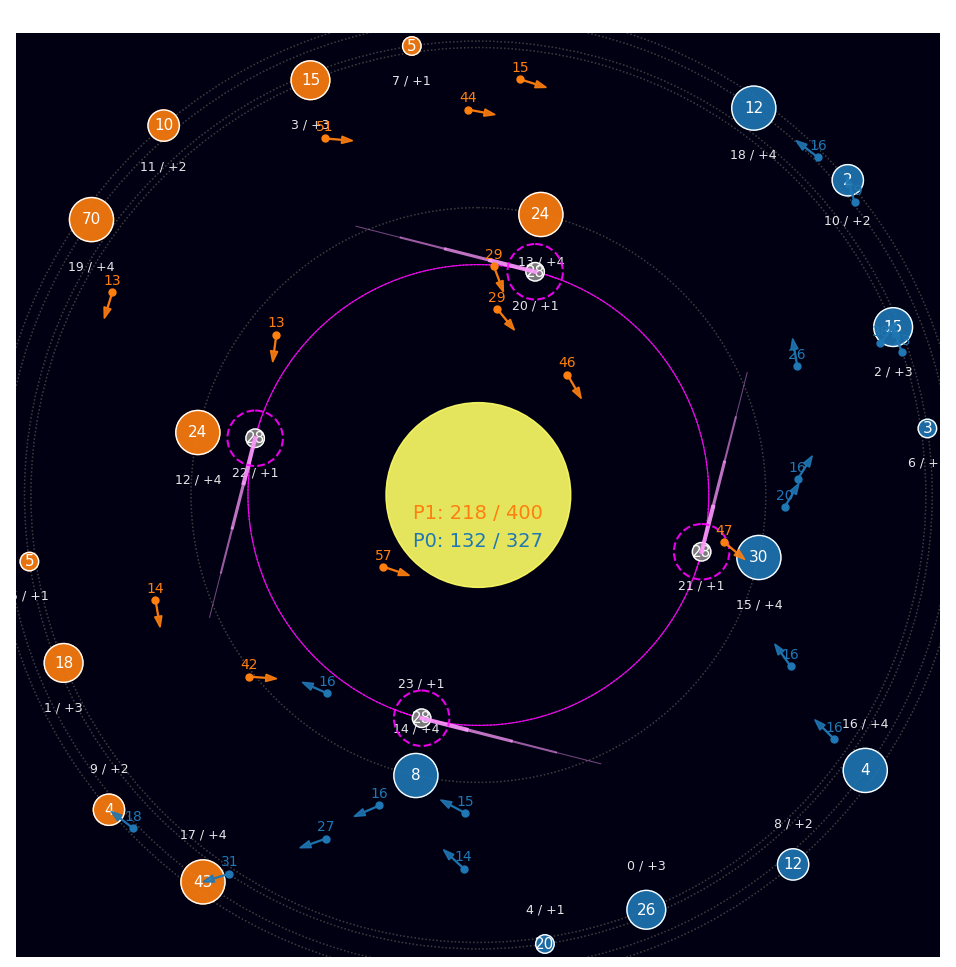

In [19]:
step = 62

# Opening position
draw_orbit_wars(env.steps[step - 1][1].observation)

In [20]:
env.steps[47][0]['observation']

{'remainingOverageTime': 59.795519,
 'step': 47,
 'planets': [[0,
   0,
   68.17313810856307,
   94.88924011533776,
   2.09861228866811,
   15,
   3],
  [1, 1, 5.110759884662244, 68.17313810856307, 2.09861228866811, 18, 3],
  [2, 0, 94.88924011533776, 31.826861891436934, 2.09861228866811, 12, 3],
  [3, 1, 31.826861891436934, 5.110759884662244, 2.09861228866811, 59, 3],
  [4, 0, 57.20389529992253, 98.593515347622, 1.0, 5, 1],
  [5, -1, 1.4064846523779977, 57.20389529992253, 1.0, 8, 1],
  [6, -1, 98.593515347622, 42.79610470007747, 1.0, 8, 1],
  [7, 1, 42.79610470007747, 1.4064846523779977, 1.0, 35, 1],
  [8, 0, 84.06094625995462, 89.98072221761515, 1.6931471805599454, 12, 2],
  [9, 1, 10.019277782384847, 84.06094625995462, 1.6931471805599454, 8, 2],
  [10, 1, 89.98072221761515, 15.939053740045381, 1.6931471805599454, 12, 2],
  [11, 1, 15.939053740045381, 10.019277782384847, 1.6931471805599454, 46, 2],
  [12, 1, 20.83228694484481, 60.79919720829843, 2.386294361119891, 25, 4],
  [13, 1, 3

## What's wrong with this agent?

The sniper agent has a few problems:
- It doesn't account for **travel time** -- the target planet produces ships while the fleet is in transit
- It sends fleets from **every** planet, even if multiple are targeting the same planet
- It ignores the **sun** -- fleets aimed through the center get destroyed
- It holds ships on planets that have no nearby targets instead of consolidating

Let's try it in a 4-player game to see how it holds up:

In [21]:
# env4 = make("orbit_wars", debug=True)
# env4.run([nearest_planet_sniper, nearest_planet_sniper, nearest_planet_sniper, nearest_planet_sniper])

# final = env4.steps[-1]
# for i, s in enumerate(final):
#     print(f"Player {i}: reward={s.reward}, status={s.status}")

# env4.render(mode="ipython", width=800, height=600)

## Making a submission

You can either submit a main.py, a tar.gz (or zip) with a main.py in it, or submit a notebook with a main.py or submission.tar.gz

There are three ways to subit.
1. using the [Submit Agent](https://www.kaggle.com/competitions/orbit-wars) button on the homepage and uploading the file
2. using the Kaggle CLI (as described in agents.py in the competition dataset)
3. submitting a notebook with a main.py or submission.tar.gz

In [22]:
# %%writefile main.py
# import math
# from kaggle_environments.envs.orbit_wars.orbit_wars import Planet

# def nearest_planet_sniper(obs):
#     moves = []
#     player = obs.get("player", 0) if isinstance(obs, dict) else obs.player
#     raw_planets = obs.get("planets", []) if isinstance(obs, dict) else obs.planets
#     planets = [Planet(*p) for p in raw_planets]

#     # Separate our planets from targets
#     my_planets = [p for p in planets if p.owner == player]
#     targets = [p for p in planets if p.owner != player]

#     if not targets:
#         return moves

#     for mine in my_planets:
#         # Find the nearest planet we don't own
#         nearest = None
#         min_dist = float('inf')
#         for t in targets:
#             dist = math.sqrt((mine.x - t.x)**2 + (mine.y - t.y)**2)
#             if dist < min_dist:
#                 min_dist = dist
#                 nearest = t

#         if nearest is None:
#             continue

#         # How many ships do we need? Target's garrison + 1
#         ships_needed = max(nearest.ships + 1, 20)

#         # Only send if we have enough
#         if mine.ships >= ships_needed:
#             # Calculate angle from our planet to the target
#             angle = math.atan2(nearest.y - mine.y, nearest.x - mine.x)
#             moves.append([mine.id, angle, ships_needed])

#     return moves

### Submit to competition

Now that we have a main.py, all you need to do is click "Submit to competition" on the right and watch your entry show up on the competition leaderboard! Best of luck!